<a href="https://colab.research.google.com/github/BusraaSarli/brain-tumor-mri-classification/blob/main/02a_resnet50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
import os, zipfile, random
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_auc_score


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Kullanılan Cihaz:", device)


drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/Brain_Tumor_MRI_Project"
DATA_DIR = "/content/brain-tumor-mri-dataset"


if not os.path.exists(DATA_DIR):
    with zipfile.ZipFile(f"{PROJECT_DIR}/brain-tumor-mri-dataset.zip", 'r') as zip_ref:
        zip_ref.extractall(DATA_DIR)
    print("Veri seti Colab diskine çıkartıldı.")


train_df = pd.read_csv(f"{PROJECT_DIR}/splits/train.csv")
val_df   = pd.read_csv(f"{PROJECT_DIR}/splits/val.csv")
test_df  = pd.read_csv(f"{PROJECT_DIR}/splits/test.csv")

CLASSES = ['glioma', 'meningioma', 'notumor', 'pituitary']
print(f"Yüklenen veri boyutları -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

Kullanılan Cihaz: cuda
Mounted at /content/drive
Veri seti Colab diskine çıkartıldı.
Yüklenen veri boyutları -> Train: 5040, Val: 1080, Test: 1080


In [8]:
IMG_SIZE = 224
BATCH_SIZE = 32
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

val_test_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

class BrainTumorDataset(Dataset):
    def __init__(self, dataframe, root_dir, transform=None):
        self.dataframe = dataframe
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.dataframe.loc[idx, "rel_path"])
        label = self.dataframe.loc[idx, "label"]
        image = Image.open(img_path)
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

train_loader = DataLoader(BrainTumorDataset(train_df, DATA_DIR, train_transforms), batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(BrainTumorDataset(val_df, DATA_DIR, val_test_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(BrainTumorDataset(test_df, DATA_DIR, val_test_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

In [9]:
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)


num_ftrs = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(num_ftrs, len(CLASSES))
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

print("ResNet50 modeli başarıyla hazırlandı!")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 176MB/s]


ResNet50 modeli başarıyla hazırlandı!


In [10]:
EPOCHS = 15
best_val_f1 = 0.0
save_path = f"{PROJECT_DIR}/best_resnet50.pth"

history = {"train_loss": [], "val_loss": [], "val_macro_f1": []}

for epoch in range(EPOCHS):

    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_loader.dataset)


    model.eval()
    val_loss = 0.0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)

            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    val_macro_f1 = f1_score(all_labels, all_preds, average='macro')

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_macro_f1"].append(val_macro_f1)

    scheduler.step(val_macro_f1)

    print(f"Epoch [{epoch+1:02d}/{EPOCHS:02d}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Macro F1: {val_macro_f1:.4f}")

    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        torch.save(model.state_dict(), save_path)
        print(f"   --> Yeni en iyi model kaydedildi! (Macro F1: {best_val_f1:.4f})")

print(f"\nEğitim tamamlandı! En yüksek Validation Macro F1: {best_val_f1:.4f}")

Epoch [01/15] | Train Loss: 0.4285 | Val Loss: 0.2637 | Val Macro F1: 0.9148
   --> Yeni en iyi model kaydedildi! (Macro F1: 0.9148)
Epoch [02/15] | Train Loss: 0.1377 | Val Loss: 0.1066 | Val Macro F1: 0.9585
   --> Yeni en iyi model kaydedildi! (Macro F1: 0.9585)
Epoch [03/15] | Train Loss: 0.0813 | Val Loss: 0.2184 | Val Macro F1: 0.9322
Epoch [04/15] | Train Loss: 0.0626 | Val Loss: 0.1109 | Val Macro F1: 0.9731
   --> Yeni en iyi model kaydedildi! (Macro F1: 0.9731)
Epoch [05/15] | Train Loss: 0.0554 | Val Loss: 0.0951 | Val Macro F1: 0.9646
Epoch [06/15] | Train Loss: 0.0493 | Val Loss: 0.0790 | Val Macro F1: 0.9732
   --> Yeni en iyi model kaydedildi! (Macro F1: 0.9732)
Epoch [07/15] | Train Loss: 0.0303 | Val Loss: 0.0695 | Val Macro F1: 0.9787
   --> Yeni en iyi model kaydedildi! (Macro F1: 0.9787)
Epoch [08/15] | Train Loss: 0.0288 | Val Loss: 0.0862 | Val Macro F1: 0.9824
   --> Yeni en iyi model kaydedildi! (Macro F1: 0.9824)
Epoch [09/15] | Train Loss: 0.0311 | Val Loss: 0

=== RESNET50 TEST SETİ SONUÇLARI ===
Macro F1-Score : 0.9870
Macro AUC-ROC  : 0.9992

              precision    recall  f1-score   support

      glioma     0.9886    0.9667    0.9775       270
  meningioma     0.9743    0.9815    0.9779       270
     notumor     0.9926    1.0000    0.9963       270
   pituitary     0.9926    1.0000    0.9963       270

    accuracy                         0.9870      1080
   macro avg     0.9870    0.9870    0.9870      1080
weighted avg     0.9870    0.9870    0.9870      1080



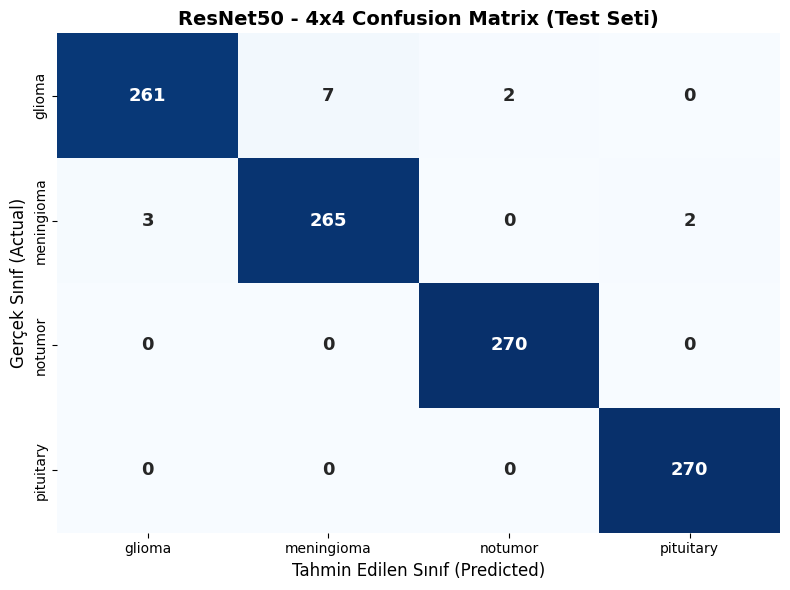

In [11]:

model.load_state_dict(torch.load(save_path))
model.eval()

test_preds, test_probs, test_labels = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(probs, dim=1)

        test_probs.extend(probs.cpu().numpy())
        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.numpy())

test_probs = np.array(test_probs)
test_preds = np.array(test_preds)
test_labels = np.array(test_labels)



macro_f1 = f1_score(test_labels, test_preds, average='macro')
macro_auc = roc_auc_score(test_labels, test_probs, multi_class='ovr', average='macro')

print("=== RESNET50 TEST SETİ SONUÇLARI ===")
print(f"Macro F1-Score : {macro_f1:.4f}")
print(f"Macro AUC-ROC  : {macro_auc:.4f}\n")
print(classification_report(test_labels, test_preds, target_names=CLASSES, digits=4))


cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, cbar=False, annot_kws={"size": 13, "weight": "bold"})
plt.title("ResNet50 - 4x4 Confusion Matrix (Test Seti)", fontsize=14, fontweight='bold')
plt.xlabel("Tahmin Edilen Sınıf (Predicted)", fontsize=12)
plt.ylabel("Gerçek Sınıf (Actual)", fontsize=12)
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/resnet50_confusion_matrix.png", dpi=300)
plt.show()